In [1]:
import os
import glob
import pandas as pd
import numpy as np

from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

%matplotlib inline

In [2]:
patron_archivos = "datasets/*.csv"
lista_archivos = sorted(glob.glob(patron_archivos))

df_lista = [pd.read_csv(archivo) for archivo in lista_archivos]
df_unificado = pd.concat(df_lista, ignore_index=True)

X = df_unificado.iloc[:, :10].values
y = df_unificado["NOX"].values

m = df_unificado.shape[0]
print(f"Total de filas y columnas del conjunto unificado: {m}")

print(("{:>12s}" * 11).format(
    'X[:,0]', 'X[:,1]', 'X[:,2]', 'X[:,3]', 'X[:,4]', 'X[:,5]', 'X[:,6]', 'X[:,7]', 'X[:,8]', 'X[:,9]', 'y (NOX)'
))
print('-' * 132)

for i in range(10):
    print(("{:12.2f}" * 11).format(X[i, 0], X[i, 1], X[i, 2], X[i, 3], X[i, 4],X[i, 5], X[i, 6], X[i, 7], X[i, 8], X[i, 9], y[i]))

Total de filas y columnas del conjunto unificado: 36733
      X[:,0]      X[:,1]      X[:,2]      X[:,3]      X[:,4]      X[:,5]      X[:,6]      X[:,7]      X[:,8]      X[:,9]     y (NOX)
------------------------------------------------------------------------------------------------------------------------------------
        4.59     1018.70       83.67        3.58       23.98     1086.20      549.83      134.67       11.90        0.33       81.95
        4.29     1018.30       84.23        3.57       23.95     1086.10      550.05      134.67       11.89        0.45       82.38
        3.90     1018.40       84.86        3.58       23.99     1086.50      550.19      135.10       12.04        0.45       83.78
        3.74     1018.30       85.43        3.58       23.91     1086.50      550.17      135.03       11.99        0.23       82.50
        3.75     1017.80       85.18        3.58       23.92     1085.90      550.00      134.67       11.91        0.27       82.03
        3.89 

In [3]:
X = np.concatenate([np.ones((m, 1)), X], axis=1)

print("\nPrimeras 3 filas y primeras 4 columnas de X:")
print(X[:3, :4])


Primeras 3 filas y primeras 4 columnas de X:
[[1.0000e+00 4.5878e+00 1.0187e+03 8.3675e+01]
 [1.0000e+00 4.2932e+00 1.0183e+03 8.4235e+01]
 [1.0000e+00 3.9045e+00 1.0184e+03 8.4858e+01]]


In [4]:
def normalEqn(X, y):

    theta = np.zeros(X.shape[1])

    theta = np.dot(np.dot(np.linalg.inv(np.dot(X.T,X)),X.T),y)

    return theta


theta = normalEqn(X, y)

print('Theta calculado a partir de la ecuación de la normal: {:s}'.format(str(theta)))

Theta calculado a partir de la ecuación de la normal: [-2.87793078e+02 -1.67250824e+00 -2.29207463e-01 -2.08347341e-01
  9.49366041e-01 -2.86907924e-01  1.53764972e+00 -1.38179642e+00
 -1.60329809e+00 -5.27938455e+00  1.80831018e+00]


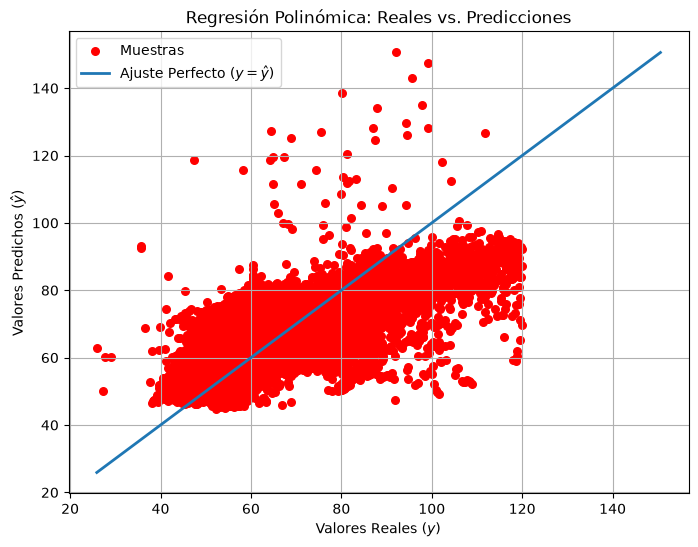

In [5]:
y_pred = np.dot(X, theta)

y_real = y.flatten()
y_pred = y_pred.flatten()

# 2. Graficar Reales vs Predichos
pyplot.figure(figsize=(8, 6))
pyplot.scatter(y_real, y_pred, color='red', s=30, label='Muestras')

# Línea de referencia y = x (predicción perfecta)
lim_min = min(y_real.min(), y_pred.min())
lim_max = max(y_real.max(), y_pred.max())
pyplot.plot([lim_min, lim_max], [lim_min, lim_max], '-', lw=2, label='Ajuste Perfecto ($y = \hat{y}$)')

pyplot.xlabel('Valores Reales ($y$)')
pyplot.ylabel('Valores Predichos ($\hat{y}$)')
pyplot.title('Regresión Polinómica: Reales vs. Predicciones')
pyplot.legend()
pyplot.grid(True)
pyplot.show()